# DBSCAN in Machine Learning:

DBSCAN is an important unsupervised machine learning clustering algorithm.  

we will explain its meaning, types and variations, complete ML workflow, data visualization, preprocessing, train/test splitting, model evaluation, and  practical Python examples with step-by-step explanations.

Because DBSCAN is an unsupervised algorithm, its workflow differs from supervised algorithms such as Linear Regression and Logistic Regression: it does not learn from a target column \(y\), and it does not require a train/test split in the usual way. However, you can use a split to study how clusters generalize to unseen data, with some important limitations explained below.

1. What is DBSCAN?

DBSCAN stands for Density-Based Spatial Clustering of Applications with Noise.

It groups data points that are close together in dense regions and identifies isolated points as noise or outliers.

In [ ]:
It groups data points that are close together in dense regions and identifies isolated points as noise or outliers.

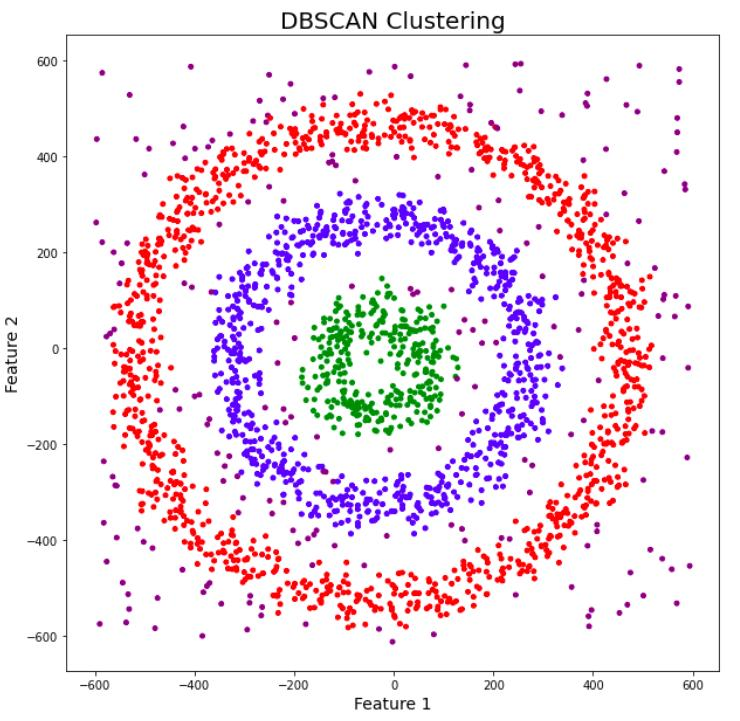
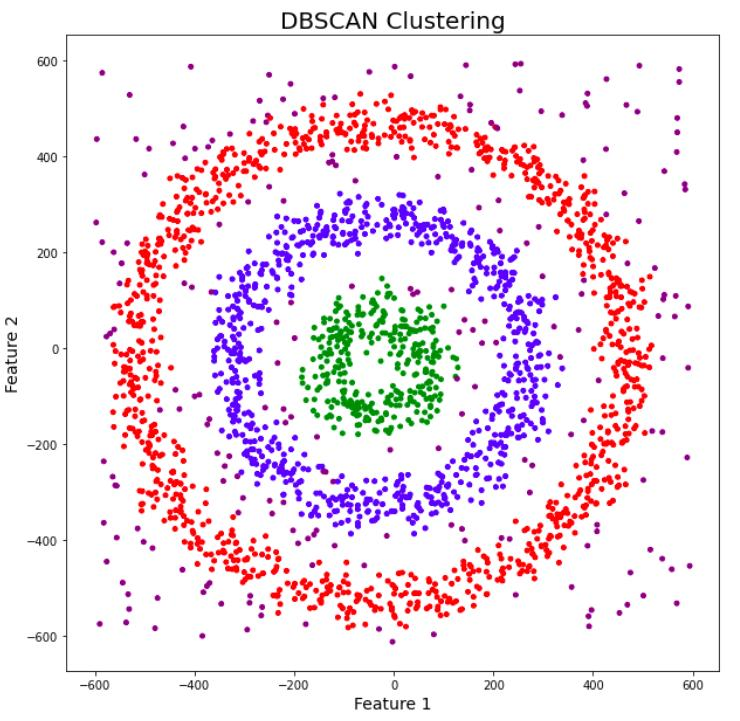
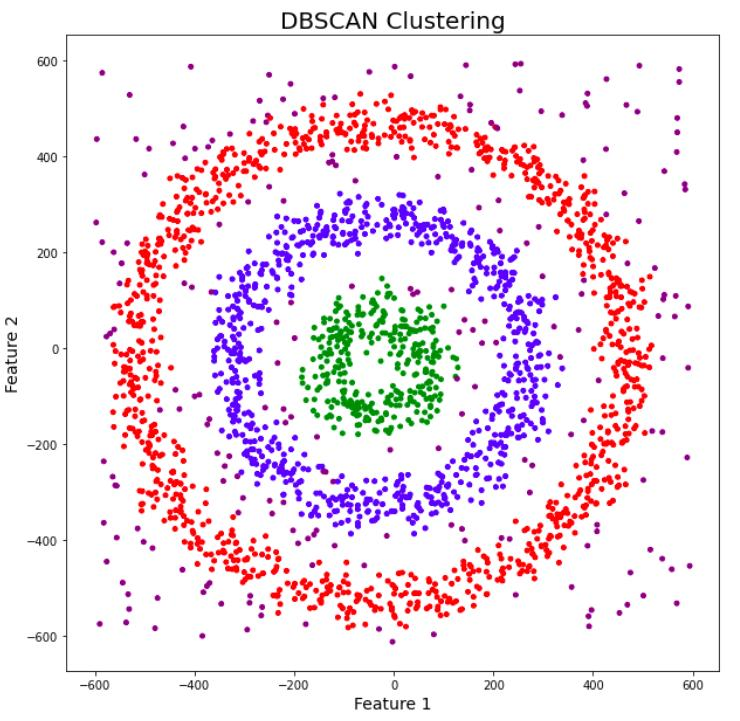
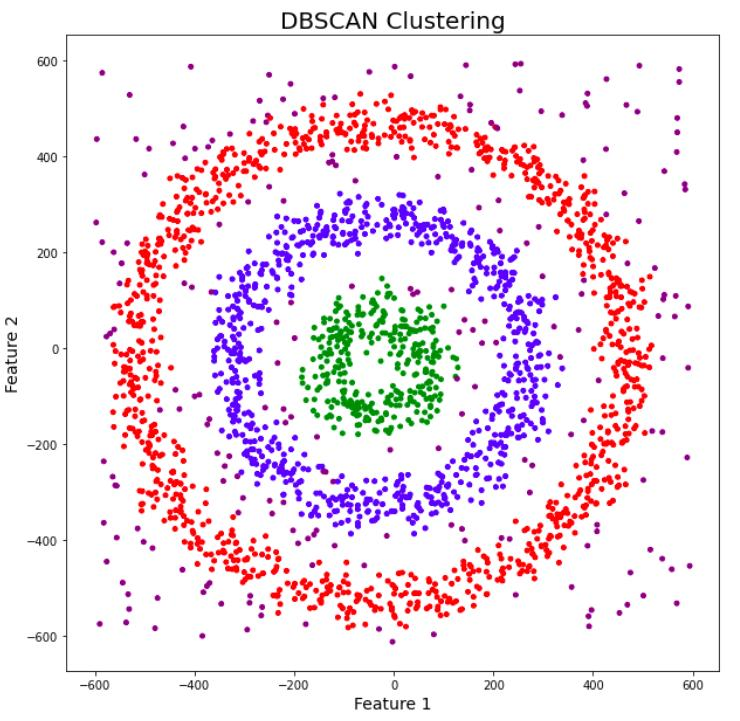
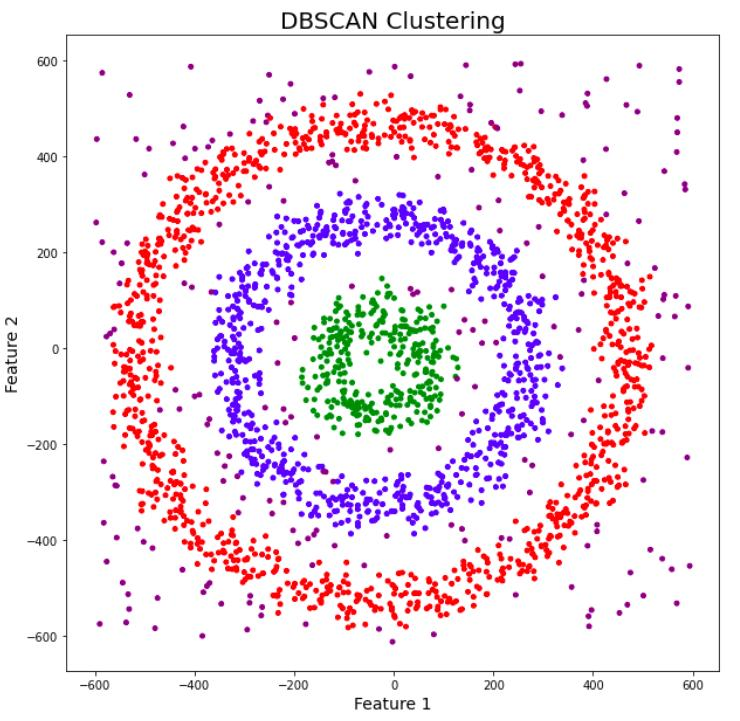
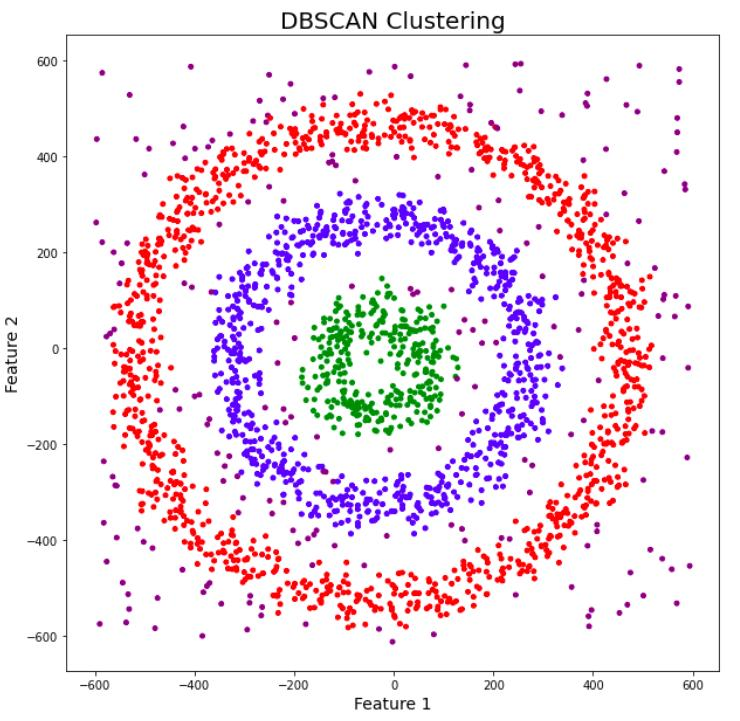
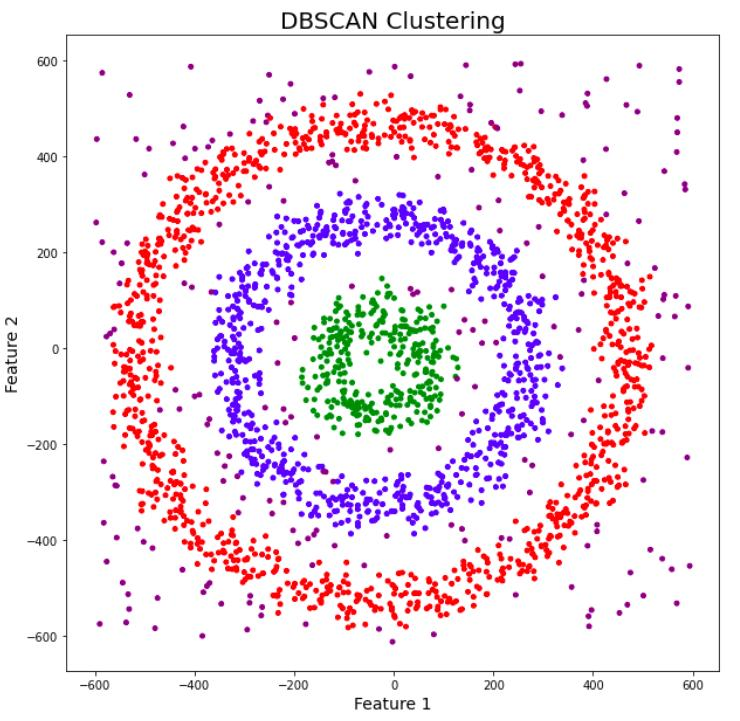
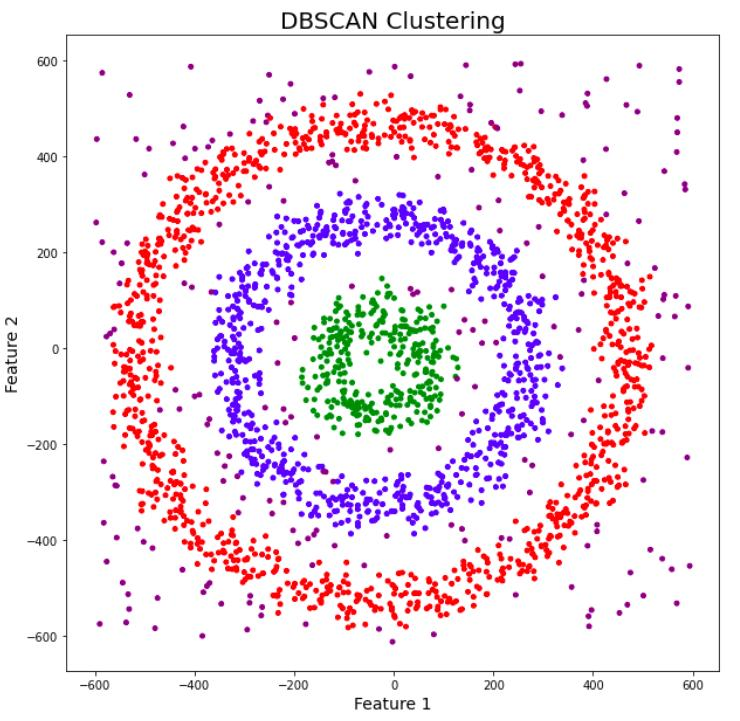
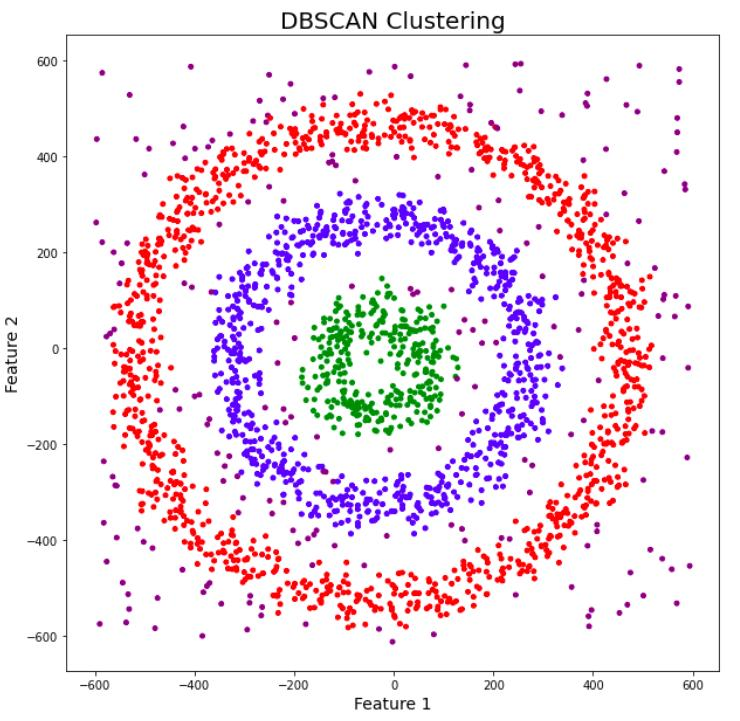
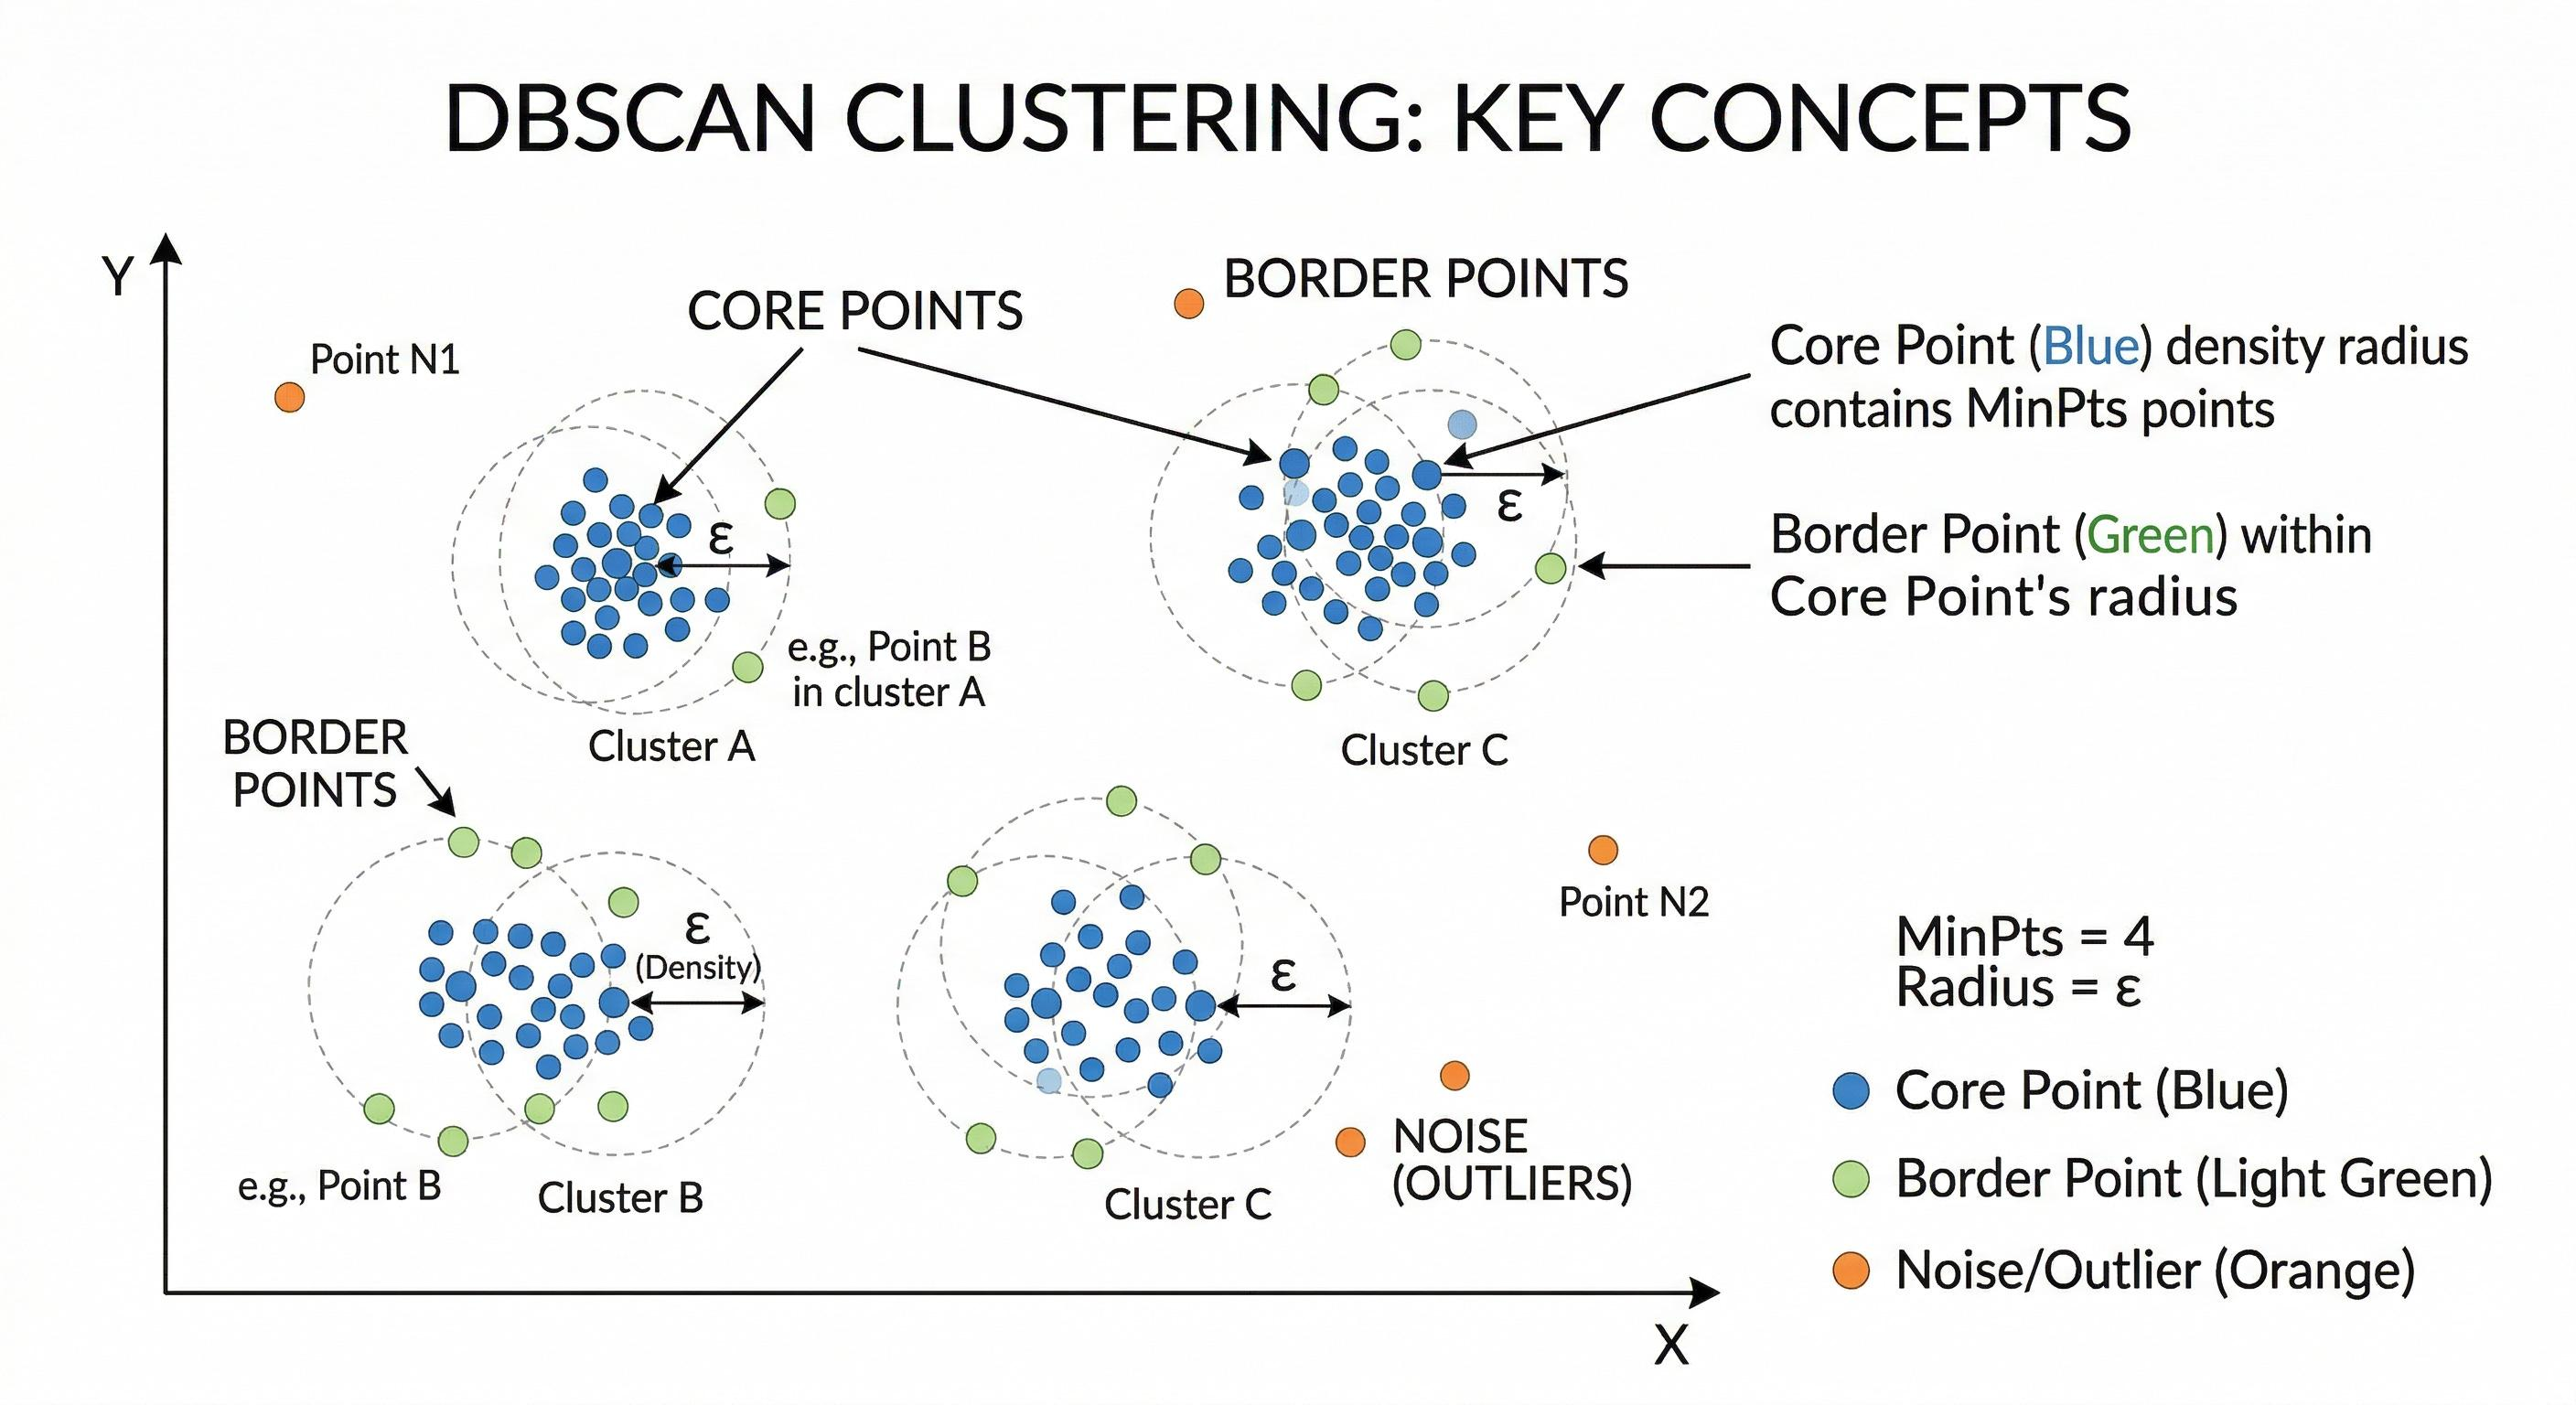


For example, imagine a shopping mall dataset containing:
- Annual income
- Spending score
- Customer age

DBSCAN can identify groups of customers with similar patterns without requiring you to specify the number of clusters in advance.

Unlike K-Means, DBSCAN can find irregularly shaped clusters and identify noise points.

# DBSCAN vs. K-Means

|Feature	|DBSCAN	|K-Means
:-----------|-------|-------
Learning type|	Unsupervised	|Unsupervised
Number of clusters|	Not specified in advance	|Must specify \(K\)
Detects outliers|	Yes, as noise	|Not inherently
Cluster shape|	Can be irregular	|Usually favors compact, spherical clusters
Scaling needed|	Usually yes|	Usually yes
Main parameters|	eps, min_samples	|n_clusters
Predict new points|	No standard predict()	|Has predict()

2. How DBSCAN works

DBSCAN uses two main parameters.

ε

1. eps — neighborhood radius

Defines how close two points must be to count as neighbors. A very small radius may produce many noise points; a very large radius may merge clusters.



N

2. min_samples — minimum neighborhood density

Specifies the minimum number of points required within a point's eps neighborhood for it to be a core point. Scikit-learn includes the point itself in this count.

# Three types of points in DBSCAN

Core point

Has at least min_samples points, including itself, within the eps radius.

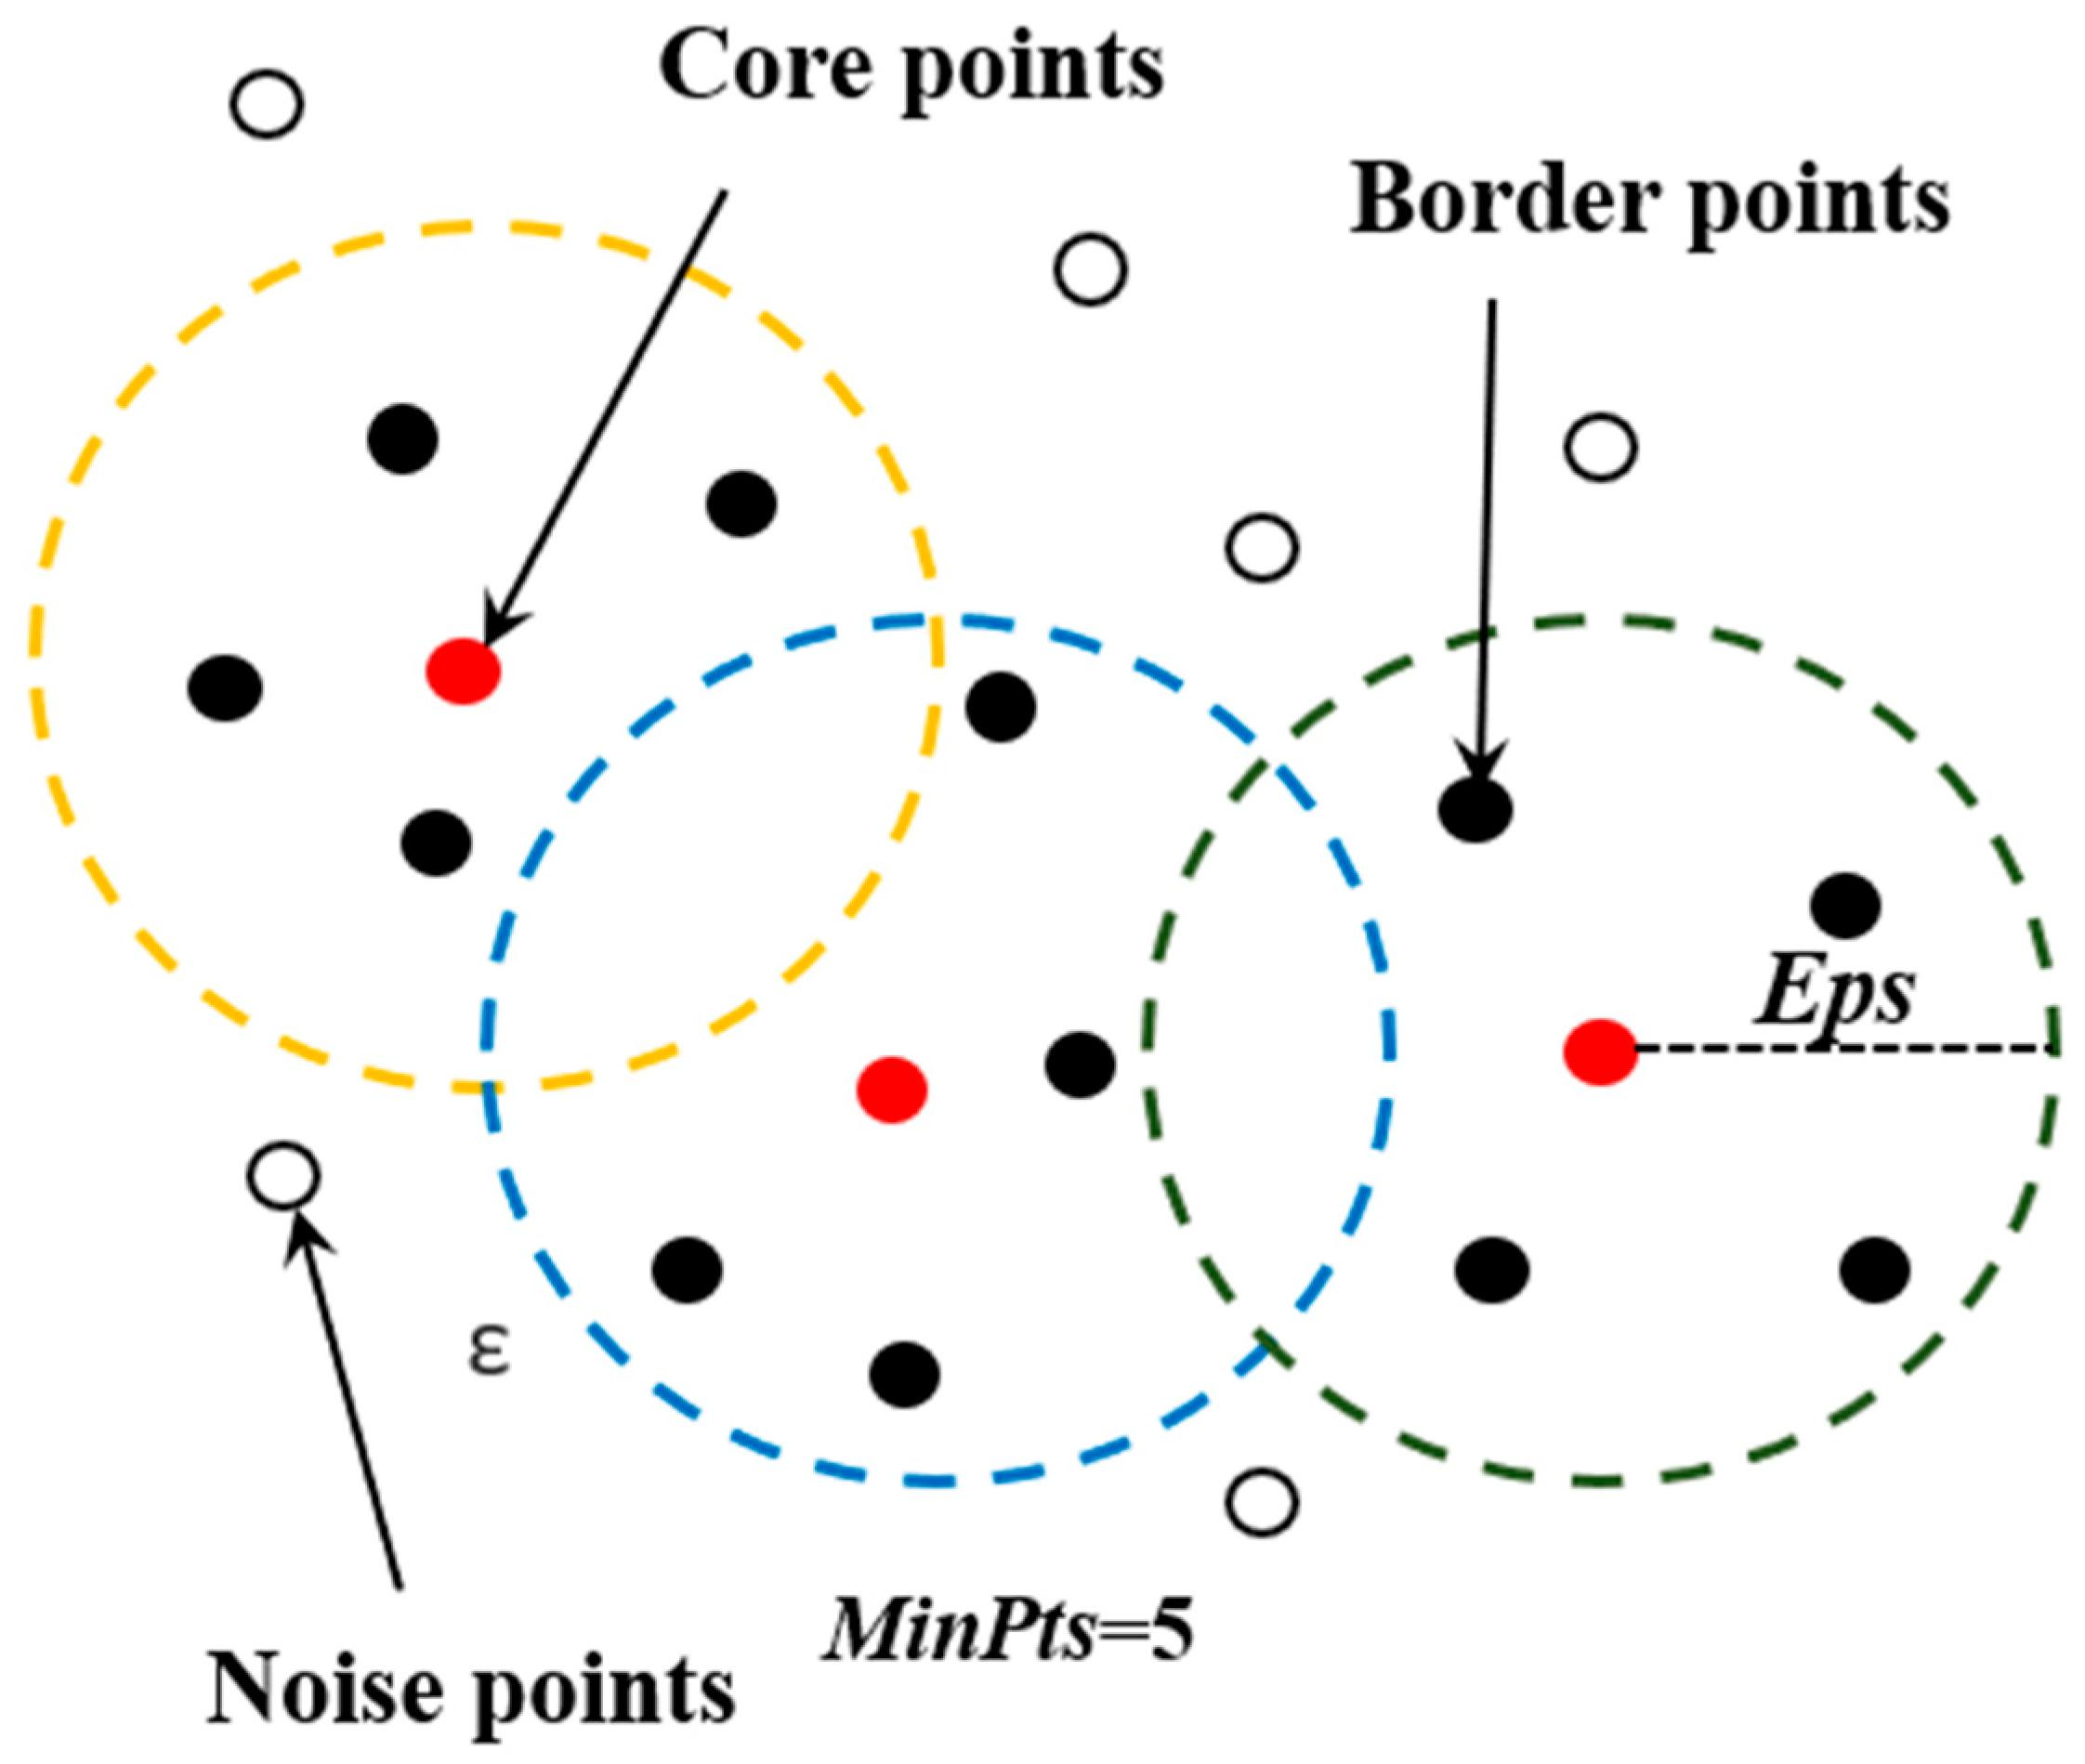

Border point

Does not have enough neighbors to be a core point, but lies within the neighborhood of a core point.

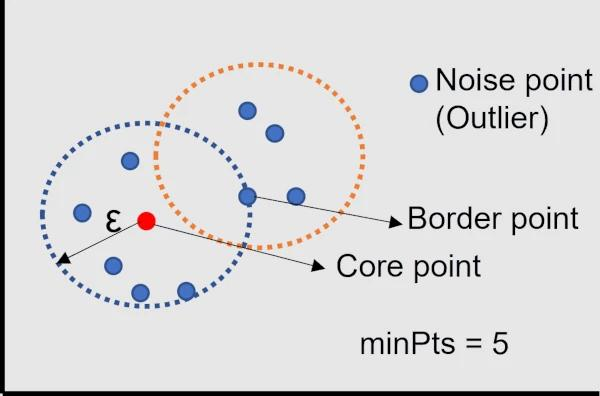

Noise point

Is not a core point and is not density-reachable from a core point. Scikit-learn assigns noise the label -1.

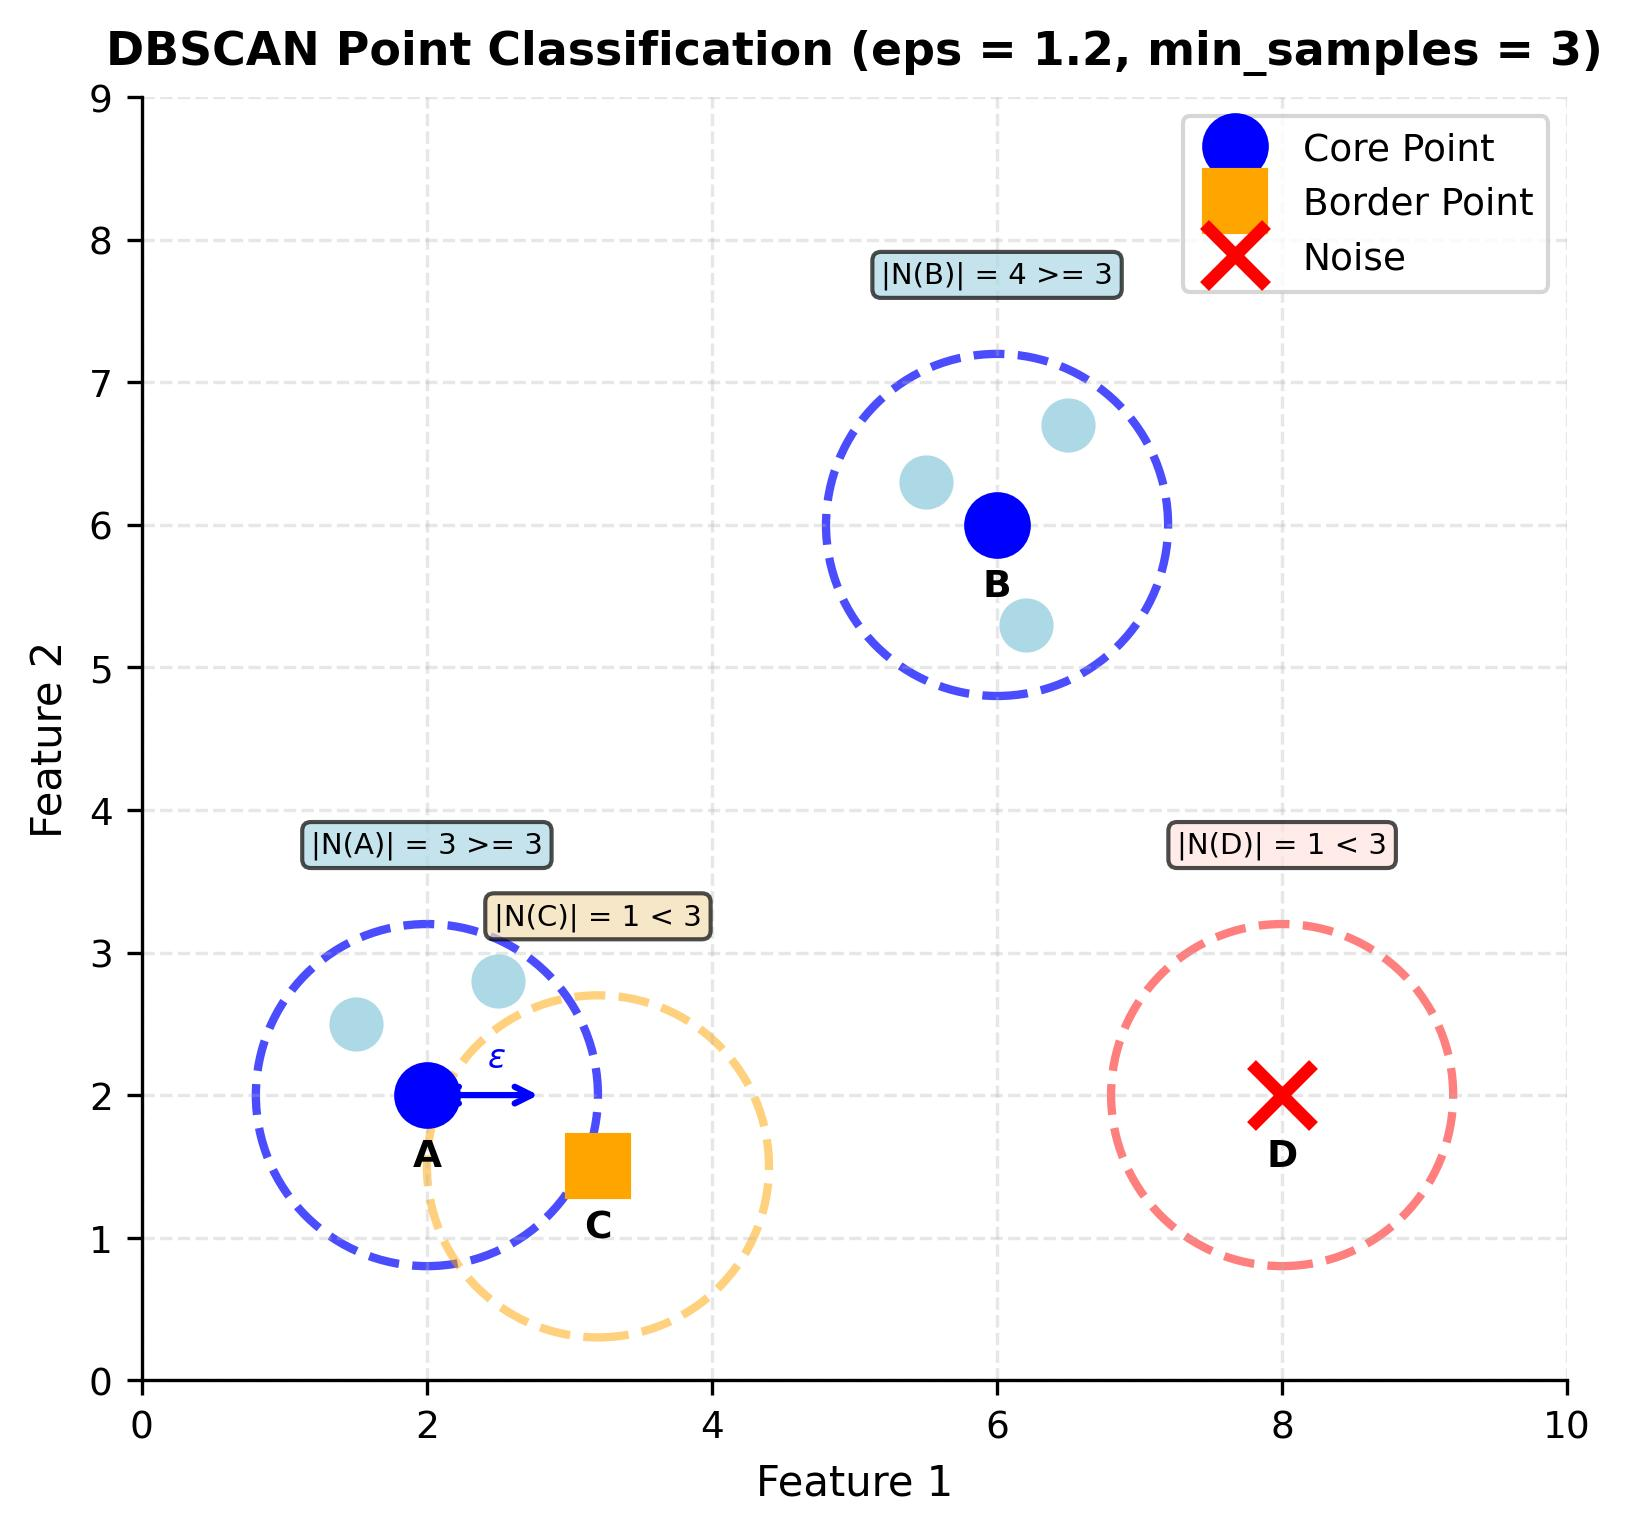

DBSCAN algorithm steps
1. Select an unvisited point.
2. Find its neighbors within the eps radius.
3. If there are too few neighbors, mark it as noise temporarily.
4. If it has enough neighbors, start a cluster.
5. Expand the cluster through density-connected core points.
6. Repeat until all points have been processed.


One useful detail: a point initially marked as noise may later be included as a border point of a cluster.

3. Types and variations of DBSCAN

DBSCAN does not have a universally agreed list of separate “types.” In practice, you learn the standard algorithm, its distance metrics, and related density-based clustering methods.

|Method or variation	|What it does	|When to use it
:-----------------------|---------------|----------------
Standard DBSCAN|	Finds dense groups and noise|	General-purpose clustering
DBSCAN with Euclidean distance|	Uses straight-line distance|	Numerical, scaled features
DBSCAN with Manhattan distance|	Uses the sum of absolute coordinate differences|	Some grid-like or high-dimensional settings
DBSCAN with cosine distance|	Compares vector directions|	Text embeddings and directional features
DBSCAN with Haversine distance|	Measures angular distance on a sphere|	Geographic latitude/longitude, with coordinates in radians
OPTICS|	Explores density structure across varying neighborhood radii|	Data with varying density
HDBSCAN|	Builds a hierarchy of density-based clusters and selects stable groups|	Data with varying densities

OPTICS and HDBSCAN are related algorithms, not simply parameter settings of standard DBSCAN. Scikit-learn documents these methods alongside DBSCAN.

4. Complete DBSCAN machine learning workflow


Here is the architecture you can follow in a real-world project.

# Important: training and testing in DBSCAN

For supervised machine learning, you typically split data into X_train, X_test, y_train, and y_test. DBSCAN is different:

-There is no target variable \(y\) required to fit DBSCAN.



-Standard DBSCAN has fit() and fit_predict(), but no standard predict() for assigning future observations to existing clusters.



-You can split data for a clustering stability experiment, but cluster IDs may differ across runs, and a test point might connect to a cluster that is not represented by the training core points.

For this reason, fit DBSCAN to the full cleaned dataset when your goal is exploratory clustering. If you need a separate test-set experiment, define an explicit rule for assigning unseen points or compare cluster stability across samples. Do not treat DBSCAN like a conventional classifier

5. Set up your Python environment

Run this in your VS Code terminal or Jupyter Notebook:

* python -m pip install numpy pandas matplotlib seaborn scikit-learn

We'll use:

- pandas and numpy for data handling.
- matplotlib and seaborn for visualization.
- scikit-learn for DBSCAN, scaling, synthetic datasets, and clustering metrics.

The five examples below are independent and use generated data, so you don't need to download a dataset.

### Example 1 — DBSCAN on two-moon data with a train/test split


**Problem statement: Identify two curved groups of data points, visualize the clusters, and demonstrate a separate test-set assignment rule.**

This is a useful first exercise because DBSCAN can identify non-circular cluster shapes that K-Means may struggle with.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors


In [2]:

# 1. Generate a sample dataset
X, true_labels = make_moons(
    n_samples=500,
    noise=0.08,
    random_state=42
)

df = pd.DataFrame(X, columns=["Feature_1", "Feature_2"])

print("First five rows:")
print(df.head())


First five rows:
   Feature_1  Feature_2
0   0.830640  -0.425055
1   0.759684   0.829335
2   1.039113  -0.488126
3  -0.281591   0.969380
4   0.315699   1.111454


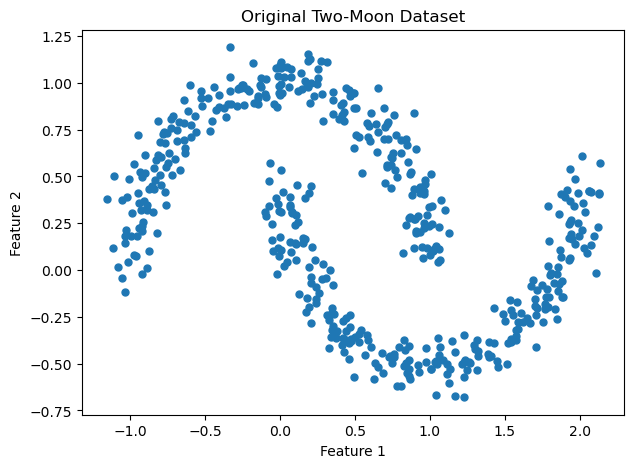

In [4]:

# 2. Visualize the original data
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], s=25)
plt.title("Original Two-Moon Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


In [5]:

# 3. Split the dataset
X_train, X_test = train_test_split(
    X, test_size=0.20, random_state=42
)


In [6]:

# 4. Scale using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [7]:

# 5. Train DBSCAN on the training set
dbscan = DBSCAN(eps=0.25, min_samples=5)
train_labels = dbscan.fit_predict(X_train_scaled)


In [8]:

# 6. Inspect the training clusters
n_clusters = len(set(train_labels) - {-1})
n_noise = np.sum(train_labels == -1)

print("\nTraining results")
print("Training records:", len(X_train))
print("Clusters found:", n_clusters)
print("Noise points:", n_noise)



Training results
Training records: 400
Clusters found: 2
Noise points: 2


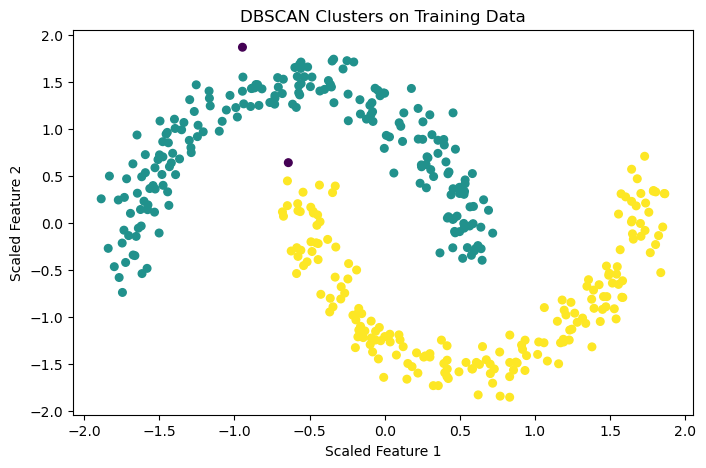

In [9]:

# 7. Visualize training clusters
plt.figure(figsize=(8, 5))
plt.scatter(
    X_train_scaled[:, 0],
    X_train_scaled[:, 1],
    c=train_labels,
    cmap="viridis",
    s=30
)
plt.title("DBSCAN Clusters on Training Data")
plt.xlabel("Scaled Feature 1")
plt.ylabel("Scaled Feature 2")
plt.show()


In [10]:

# 8. Demonstration-only assignment rule for test points
# Assign a test point to the nearest training core point
# if that point is within eps; otherwise mark it as noise.

def assign_to_nearest_core(X_new, model):
    predictions = np.full(len(X_new), -1, dtype=int)

    if len(model.core_sample_indices_) == 0:
        return predictions

    core_points = model.components_
    core_labels = model.labels_[model.core_sample_indices_]

    distances = np.linalg.norm(
        X_new[:, None, :] - core_points[None, :, :],
        axis=2
    )

    nearest_indices = distances.argmin(axis=1)
    nearest_distances = distances[
        np.arange(len(X_new)), nearest_indices
    ]

    accepted = nearest_distances <= model.eps
    predictions[accepted] = core_labels[nearest_indices[accepted]]

    return predictions

test_labels = assign_to_nearest_core(X_test_scaled, dbscan)

print("\nTest-set assignment demonstration")
print("Test records:", len(X_test))
print("Assigned to existing clusters:", np.sum(test_labels != -1))
print("Unassigned / noise:", np.sum(test_labels == -1))



Test-set assignment demonstration
Test records: 100
Assigned to existing clusters: 99
Unassigned / noise: 1


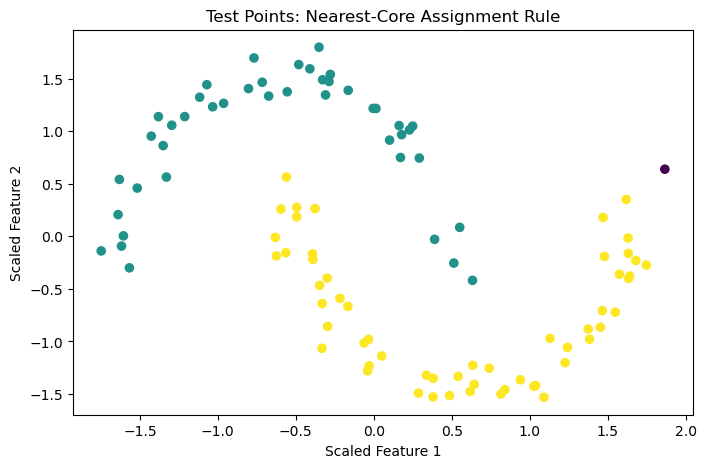

In [11]:

# 9. Visualize test assignments
plt.figure(figsize=(8, 5))
plt.scatter(
    X_test_scaled[:, 0],
    X_test_scaled[:, 1],
    c=test_labels,
    cmap="viridis",
    s=35
)
plt.title("Test Points: Nearest-Core Assignment Rule")
plt.xlabel("Scaled Feature 1")
plt.ylabel("Scaled Feature 2")
plt.show()


Step-by-step explanation

1. make_moons() generates two crescent-shaped groups.
2. train_test_split() reserves 20% of observations for a separate experiment.
3. StandardScaler puts both features on comparable scales.
4. DBSCAN(eps=0.25, min_samples=5) discovers clusters in the training data.
5. fit_predict() learns clusters and returns a label for each training observation.
6. core_sample_indices_ identifies core observations; components_ contains the corresponding scaled coordinates.
7. The custom function assigns a test point to its nearest core point if the distance is at most eps; otherwise it returns -1.


- **Important limitation:** The custom test assignment is a nearest-core heuristic, not an official DBSCAN prediction method. It does not reproduce DBSCAN's complete density-connectivity rules, so use it as a teaching demonstration rather than a definitive test metric.

# Example 2 — Retail customer segmentation

**Problem statement:** Group customers using annual income, spending score, and age. Identify customer groups and potential outliers.

-Business use case: help a retail business explore high-spending customers, lower-spending customers, and unusual customer profiles.

   Annual_Income  Spending_Score        Age
0      18.711097       28.443434  18.000000
1      62.460488       47.291613  52.580250
2      48.888274       44.221076  50.262869
3      39.855093       32.227257  18.000000
4      59.443921       37.645406  41.213751
       Annual_Income  Spending_Score         Age
count     450.000000      450.000000  450.000000
mean       50.587802       49.678382   37.274001
std        21.421414       24.020850   12.192451
min        11.335385        2.311129   18.000000
25%        28.829813       29.780843   27.128898
50%        51.168946       45.302418   35.854753
75%        70.428198       74.132836   48.652003
max        95.586878      100.000000   63.514615


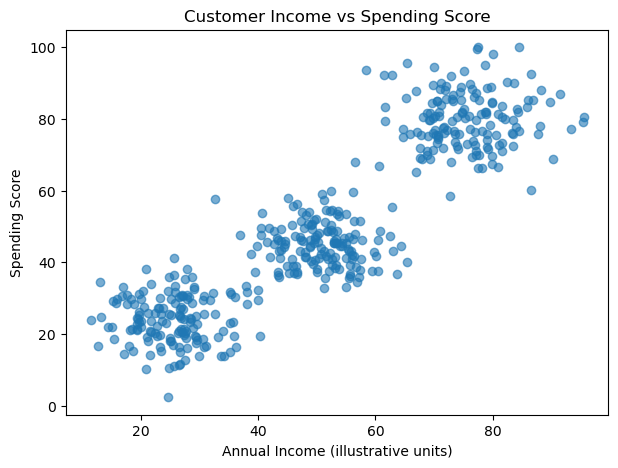


Cluster counts:
Cluster
-1      2
 0    300
 1    148
Name: count, dtype: int64

Number of clusters: 2
Noise points: 2


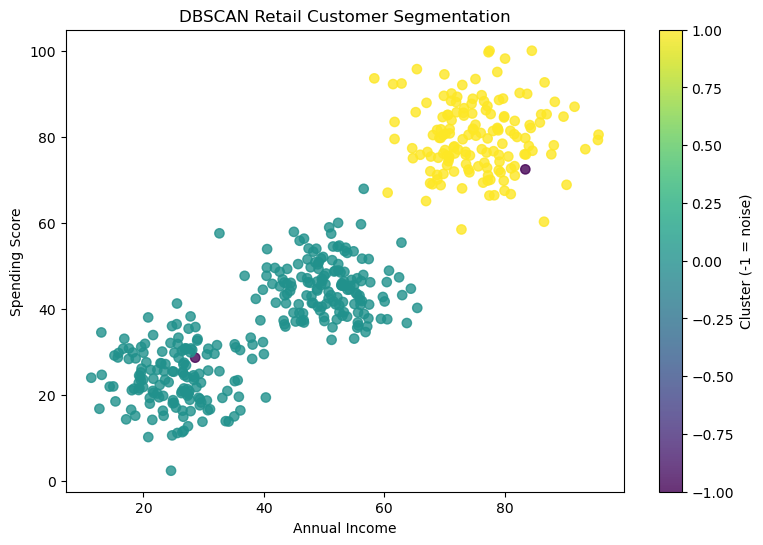


Average profile for each cluster:
         Annual_Income  Spending_Score    Age
Cluster                                      
0                38.23           34.76  38.26
1                75.57           79.90  35.05


In [12]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs

# 1. Generate illustrative customer data
rng = np.random.default_rng(42)

centers = [
    [25, 25, 25],
    [75, 80, 35],
    [50, 45, 50]
]

X, _ = make_blobs(
    n_samples=450,
    centers=centers,
    cluster_std=[7, 8, 6],
    random_state=42
)

df = pd.DataFrame(
    X, columns=["Annual_Income", "Spending_Score", "Age"]
)

# Make the example values interpretable
df["Annual_Income"] = df["Annual_Income"].clip(10, 100)
df["Spending_Score"] = df["Spending_Score"].clip(1, 100)
df["Age"] = df["Age"].clip(18, 75)

print(df.head())
print(df.describe())

# 2. EDA: inspect feature relationships
plt.figure(figsize=(7, 5))
plt.scatter(df["Annual_Income"], df["Spending_Score"], alpha=0.6)
plt.title("Customer Income vs Spending Score")
plt.xlabel("Annual Income (illustrative units)")
plt.ylabel("Spending Score")
plt.show()

# 3. Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# 4. Fit DBSCAN
model = DBSCAN(eps=0.55, min_samples=6)
df["Cluster"] = model.fit_predict(X_scaled)

# 5. Summarize results
print("\nCluster counts:")
print(df["Cluster"].value_counts().sort_index())

n_clusters = df["Cluster"].nunique() - int(-1 in df["Cluster"].unique())
print("\nNumber of clusters:", n_clusters)
print("Noise points:", (df["Cluster"] == -1).sum())

# 6. Plot clusters using two features
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    c=df["Cluster"],
    cmap="viridis",
    s=45,
    alpha=0.8
)
plt.title("DBSCAN Retail Customer Segmentation")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.colorbar(scatter, label="Cluster (-1 = noise)")
plt.show()

# 7. Interpret the cluster profiles
print("\nAverage profile for each cluster:")
print(
    df[df["Cluster"] != -1]
    .groupby("Cluster")[
        ["Annual_Income", "Spending_Score", "Age"]
    ]
    .mean()
    .round(2)
)


What to understand

- StandardScaler() is important because income, spending score, and age have different ranges.
- DBSCAN uses all three features to form clusters.
- The scatter plot displays only income and spending score. A point that looks close to another in 2D may still be far away in the third dimension, age.
- Cluster -1 represents noise, not a customer segment.
- Group averages help you describe customer profiles, but the final interpretation depends on the observed results.

The generated data is illustrative, not real customer purchase data.

### Example 3 — Student performance grouping
 - **Problem statement:** Group students based on study hours, attendance percentage, and exam score.

- Business or education use case: identify patterns such as students with high attendance and strong performance, or students whose results may merit additional support.

   Study_Hours  Attendance  Exam_Score
0     9.701070   78.601758   69.382459
1     7.358128   83.254508   66.529881
2    12.000000   85.815243   83.454700
3     9.360154   98.634780   92.228593
4     1.858098   54.801832   42.240581
       Study_Hours  Attendance  Exam_Score
count       300.00      300.00      300.00
mean          5.35       77.93       67.99
std           4.15       14.67       18.92
min           0.00       48.56       36.73
25%           1.64       62.23       47.52
50%           4.94       80.15       69.27
75%           9.32       90.86       85.78
max          12.00      100.00      100.00


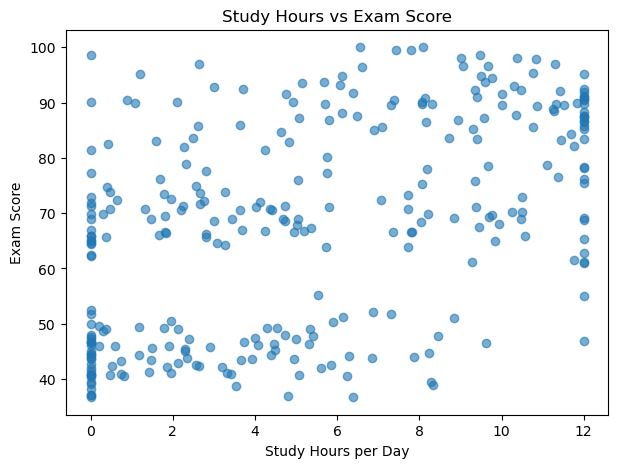


Student cluster counts:
Cluster
0    201
1     99
Name: count, dtype: int64


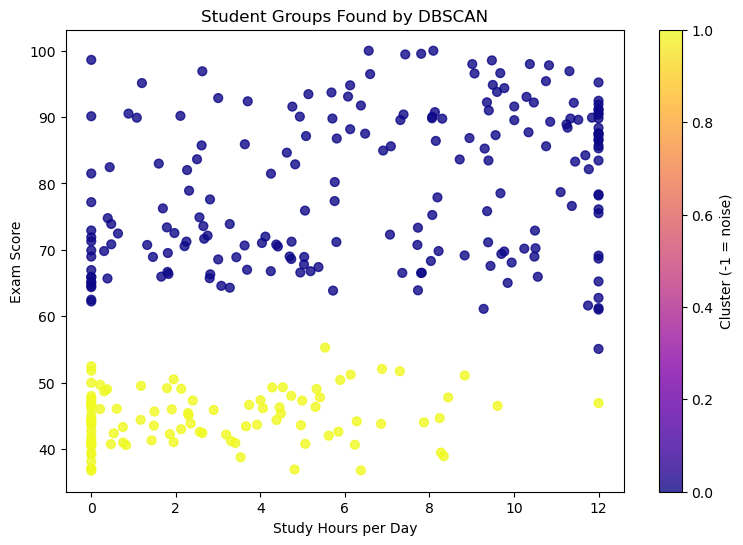


Cluster profiles:
         Study_Hours  Attendance  Exam_Score
Cluster                                     
0               6.59       86.83       79.46
1               2.82       59.85       44.70


In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# 1. Create illustrative student data
X, _ = make_blobs(
    n_samples=300,
    centers=[
        [2, 60, 45],
        [5, 80, 70],
        [8, 95, 90]
    ],
    cluster_std=[4, 5, 5],
    random_state=21
)

df = pd.DataFrame(
    X, columns=["Study_Hours", "Attendance", "Exam_Score"]
)

df["Study_Hours"] = df["Study_Hours"].clip(0, 12)
df["Attendance"] = df["Attendance"].clip(0, 100)
df["Exam_Score"] = df["Exam_Score"].clip(0, 100)

print(df.head())
print(df.describe().round(2))

# 2. EDA visualization
plt.figure(figsize=(7, 5))
plt.scatter(df["Study_Hours"], df["Exam_Score"], alpha=0.6)
plt.title("Study Hours vs Exam Score")
plt.xlabel("Study Hours per Day")
plt.ylabel("Exam Score")
plt.show()

# 3. Scale the input features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# 4. Apply DBSCAN
model = DBSCAN(eps=0.65, min_samples=6)
df["Cluster"] = model.fit_predict(X_scaled)

# 5. Print cluster counts
print("\nStudent cluster counts:")
print(df["Cluster"].value_counts().sort_index())

# 6. Visualize discovered groups
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df["Study_Hours"],
    df["Exam_Score"],
    c=df["Cluster"],
    cmap="plasma",
    s=40,
    alpha=0.8
)
plt.title("Student Groups Found by DBSCAN")
plt.xlabel("Study Hours per Day")
plt.ylabel("Exam Score")
plt.colorbar(scatter, label="Cluster (-1 = noise)")
plt.show()

# 7. Compare cluster profiles
profiles = (
    df[df["Cluster"] != -1]
    .groupby("Cluster")[
        ["Study_Hours", "Attendance", "Exam_Score"]
    ]
    .mean()
    .round(2)
)

print("\nCluster profiles:")
print(profiles)


### How to interpret results
*Suppose one cluster has higher average attendance and exam scores than another. You could describe it as a higher-performing group in this dataset.

- -- Do not assume that studying more necessarily causes better scores. Clustering identifies patterns, not causal relationships. Also, noise points may be unusual observations rather than poorly performing students.

### Example 4 — Employee analytics

**Problem statement:**  Group employees using years of experience, performance score, and monthly working hours. Examine whether DBSCAN discovers distinct employee profiles or identifies unusual working patterns.

- Business use case: workforce analysis, workload planning, and identifying records that deserve further investigation. Clusters should not be used alone to make employment decisions.

   Experience_Years  Performance_Score  Monthly_Hours
0          6.801821          74.387887     176.942813
1          0.246983          56.714234     151.127900
2          0.776285          54.884347     150.511728
3          4.610613          72.745286     179.631385
4          1.960229          55.090345     153.694863
       Experience_Years  Performance_Score  Monthly_Hours
count            350.00             350.00         350.00
mean               5.77              71.59         183.35
std                3.61              12.81          28.76
min                0.00              50.14         146.07
25%                2.61              55.81         151.15
50%                5.02              74.96         179.85
75%                8.98              83.97         219.00
max               14.61              89.55         224.74


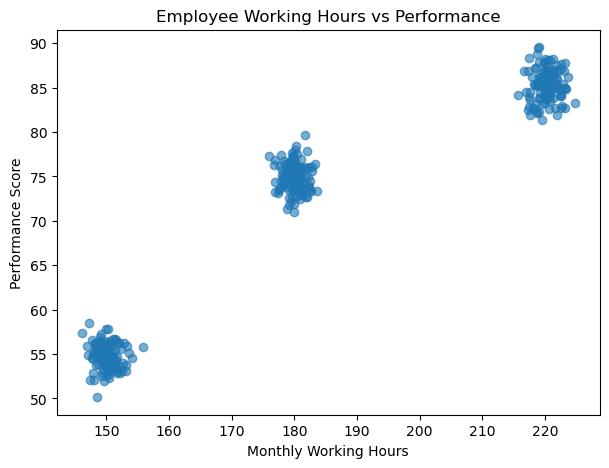


Employee cluster counts:
Cluster
0    117
1    117
2    116
Name: count, dtype: int64

Noise records: 0


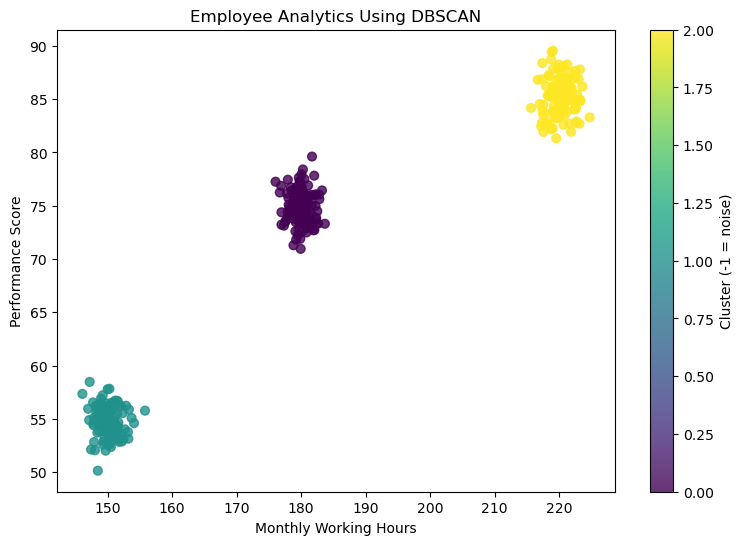


Employee cluster profiles:
         Experience_Years  Performance_Score  Monthly_Hours
Cluster                                                    
0                    5.08              74.90         179.95
1                    2.13              54.71         150.18
2                   10.12              85.29         220.23


In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# 1. Create illustrative employee data
X, _ = make_blobs(
    n_samples=350,
    centers=[
        [2, 55, 150],
        [5, 75, 180],
        [10, 85, 220]
    ],
    cluster_std=[1.5, 1.5, 1.8],
    random_state=42
)

df = pd.DataFrame(
    X,
    columns=["Experience_Years", "Performance_Score", "Monthly_Hours"]
)

df["Experience_Years"] = df["Experience_Years"].clip(0, 40)
df["Performance_Score"] = df["Performance_Score"].clip(0, 100)
df["Monthly_Hours"] = df["Monthly_Hours"].clip(60, 350)

print(df.head())
print(df.describe().round(2))

# 2. EDA: inspect working hours and performance
plt.figure(figsize=(7, 5))
plt.scatter(
    df["Monthly_Hours"],
    df["Performance_Score"],
    alpha=0.6
)
plt.title("Employee Working Hours vs Performance")
plt.xlabel("Monthly Working Hours")
plt.ylabel("Performance Score")
plt.show()

# 3. Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# 4. Fit DBSCAN
model = DBSCAN(eps=0.60, min_samples=7)
df["Cluster"] = model.fit_predict(X_scaled)

# 5. Summarize cluster counts
print("\nEmployee cluster counts:")
print(df["Cluster"].value_counts().sort_index())

print("\nNoise records:", (df["Cluster"] == -1).sum())

# 6. Visualize clusters
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df["Monthly_Hours"],
    df["Performance_Score"],
    c=df["Cluster"],
    cmap="viridis",
    s=40,
    alpha=0.8
)
plt.title("Employee Analytics Using DBSCAN")
plt.xlabel("Monthly Working Hours")
plt.ylabel("Performance Score")
plt.colorbar(scatter, label="Cluster (-1 = noise)")
plt.show()

# 7. Compare employee profiles
print("\nEmployee cluster profiles:")
print(
    df[df["Cluster"] != -1]
    .groupby("Cluster")[
        ["Experience_Years", "Performance_Score", "Monthly_Hours"]
    ]
    .mean()
    .round(2)
)


What to learn
- Three input features are used to form clusters.
- The visualization shows two features, while experience also influences the result.
- Group profiles summarize the characteristics of each cluster.
- A noise point might represent an unusual combination of experience, performance, and hours; it is not automatically an error or an underperforming employee.


This is synthetic data for practice, not actual employee records.

## Example 5 — Detect anomalies in e-commerce transactions
**Problem statement:** Identify dense groups of transactions and flag isolated records using transaction amount and transaction frequency.

Business use case: exploratory fraud detection, unusual purchasing behavior, and transaction-quality checks. DBSCAN is an anomaly-screening method here, not a fraud classifier.

   Transaction_Amount  Transaction_Frequency
0          234.379536               2.018264
1           56.180423               5.513786
2          121.986646               3.601110
3          234.680283               1.728609
4          267.693798               1.606273

Summary statistics:
       Transaction_Amount  Transaction_Frequency
count              465.00                 465.00
mean               156.51                   3.62
std                124.23                   2.09
min                 11.10                   1.00
25%                 57.51                   2.31
50%                123.64                   3.09
75%                238.86                   4.61
max                790.25                  14.79


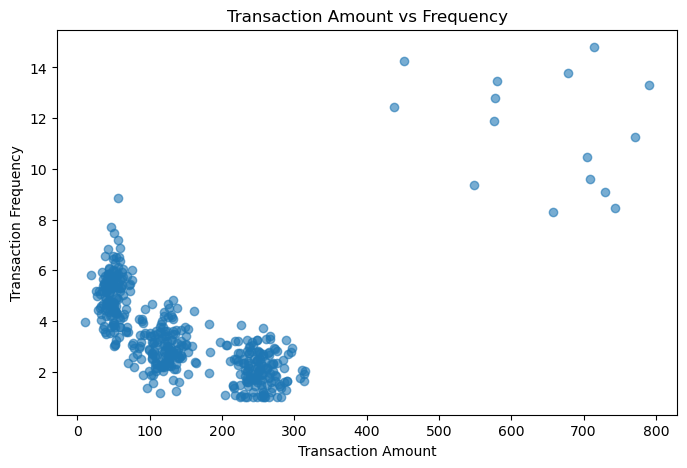


Cluster counts:
Cluster
-1     16
 0    449
Name: count, dtype: int64

Number of flagged transactions: 16

Flagged transaction examples:
     Transaction_Amount  Transaction_Frequency  Cluster
217           56.180572               8.852731       -1
450          709.582419               9.590671       -1
451          575.551376              11.882094       -1
452          743.439168               8.446721       -1
453          678.947212              13.793418       -1
454          437.670939              12.421651       -1
455          790.248941              13.306614       -1
456          704.455881              10.481682       -1
457          714.425722              14.794886       -1
458          451.245453              14.251848       -1
459          580.154375              13.448684       -1
460          548.319210               9.362471       -1
461          770.705996              11.267047       -1
462          657.546048               8.306626       -1
463          729.10464

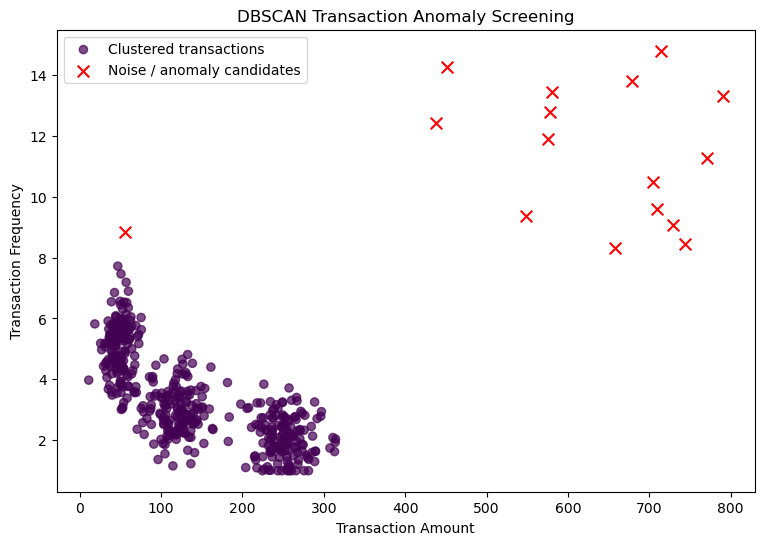

In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# 1. Generate normal transaction patterns
X_normal, _ = make_blobs(
    n_samples=450,
    centers=[
        [50, 5],
        [120, 3],
        [250, 2]
    ],
    cluster_std=[
        [12, 1.0],
        [20, 0.8],
        [25, 0.7]
    ],
    random_state=42
)

# 2. Add unusual transactions
rng = np.random.default_rng(42)

X_anomalies = np.column_stack([
    rng.uniform(400, 800, 15),
    rng.uniform(8, 15, 15)
])

X = np.vstack([X_normal, X_anomalies])

df = pd.DataFrame(
    X,
    columns=["Transaction_Amount", "Transaction_Frequency"]
)

df["Transaction_Amount"] = df["Transaction_Amount"].clip(lower=1)
df["Transaction_Frequency"] = df["Transaction_Frequency"].clip(lower=1)

print(df.head())
print("\nSummary statistics:")
print(df.describe().round(2))

# 3. Visualize the original transactions
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Transaction_Amount"],
    df["Transaction_Frequency"],
    alpha=0.6
)
plt.title("Transaction Amount vs Frequency")
plt.xlabel("Transaction Amount")
plt.ylabel("Transaction Frequency")
plt.show()

# 4. Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# 5. Fit DBSCAN
model = DBSCAN(eps=0.35, min_samples=8)
df["Cluster"] = model.fit_predict(X_scaled)

# 6. Identify noise points
df["Is_Noise"] = df["Cluster"] == -1

print("\nCluster counts:")
print(df["Cluster"].value_counts().sort_index())

print("\nNumber of flagged transactions:", df["Is_Noise"].sum())

print("\nFlagged transaction examples:")
print(df.loc[df["Is_Noise"], [
    "Transaction_Amount",
    "Transaction_Frequency",
    "Cluster"
]].head(20))

# 7. Visualize clusters and noise
plt.figure(figsize=(9, 6))

normal_mask = ~df["Is_Noise"]
noise_mask = df["Is_Noise"]

plt.scatter(
    df.loc[normal_mask, "Transaction_Amount"],
    df.loc[normal_mask, "Transaction_Frequency"],
    c=df.loc[normal_mask, "Cluster"],
    cmap="viridis",
    s=35,
    alpha=0.7,
    label="Clustered transactions"
)

plt.scatter(
    df.loc[noise_mask, "Transaction_Amount"],
    df.loc[noise_mask, "Transaction_Frequency"],
    color="red",
    marker="x",
    s=70,
    label="Noise / anomaly candidates"
)

plt.title("DBSCAN Transaction Anomaly Screening")
plt.xlabel("Transaction Amount")
plt.ylabel("Transaction Frequency")
plt.legend()
plt.show()


What to learn

- np.vstack() adds the unusual transaction records to the ordinary records.
- DBSCAN labels points outside the discovered dense regions as -1.
- Is_Noise converts those labels into a Boolean flag.
- The red crosses highlight candidate anomalies for investigation.


A transaction may be unusual but legitimate, or fraudulent but located within a dense region. A real fraud project needs labeled historical outcomes, additional validation, and appropriate investigation procedures.

6. How to choose the best eps value

* Choosing eps is often the most important part of a DBSCAN project. Rather than guessing, use a k-distance plot to estimate a useful radius.

* The following code can be added to any of the examples after you have selected and scaled the feature matrix.

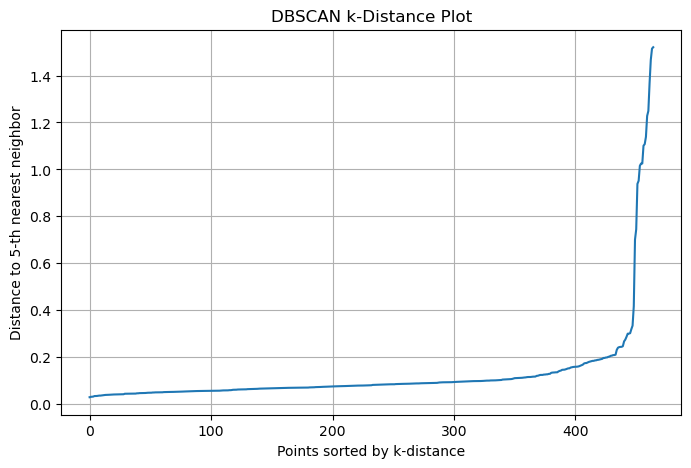

In [16]:

import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# X_scaled is the scaled feature matrix from an example.
min_samples = 5

neighbors = NearestNeighbors(
    n_neighbors=min_samples
)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Sort each point's distance to its k-th nearest neighbor
k_distances = sorted(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.title("DBSCAN k-Distance Plot")
plt.xlabel("Points sorted by k-distance")
plt.ylabel(f"Distance to {min_samples}-th nearest neighbor")
plt.grid(True)
plt.show()


How to read the plot:

1. Find the point where the curve starts rising sharply.
2. Use the distance near that bend as a candidate eps.
3. Try several nearby eps values and reasonable min_samples values.
4. Compare the number of clusters, noise proportion, cluster profiles, and evaluation scores.


The bend is a heuristic, not a guaranteed optimal setting. If your data has widely varying densities, a single eps may not work well for every group.

7. Evaluate DBSCAN results


- Unlike classification algorithms, DBSCAN does not normally use accuracy, precision, recall, or F1-score because there is no required target label.

- Use these evaluation methods instead.

|Metric or check	|Purpose
:-------------------|--------
Number of clusters|	Measures how many groups were discovered
Noise percentage|	Shows how many points were classified as noise
Silhouette score|	Measures cluster separation and cohesion
Adjusted Rand Index (ARI)|	Compares discovered clusters with known true labels, when available
Cluster profiles|	Helps determine whether groups have meaningful real-world differences
Stability|	Checks whether clusters remain similar when parameters or samples change

#### Silhouette score example

Add this after fitting DBSCAN in any of the examples.

In [17]:

from sklearn.metrics import silhouette_score
import numpy as np

labels = model.labels_

# Exclude noise points for this particular analysis
mask = labels != -1
cluster_labels = labels[mask]
cluster_count = len(np.unique(cluster_labels))

if cluster_count >= 2 and mask.sum() > cluster_count:
    score = silhouette_score(
        X_scaled[mask],
        cluster_labels
    )
    print("Silhouette score:", round(score, 3))
else:
    print(
        "Silhouette score is not meaningful here: "
        "at least two non-noise clusters are required."
    )


Silhouette score is not meaningful here: at least two non-noise clusters are required.


A silhouette score ranges from -1 to 1; higher scores generally indicate better separation. Excluding noise makes this score easier to interpret for the discovered clusters, but it also means the score does not evaluate how well the algorithm handled the noise points. Always report the noise percentage alongside it.

# 8. Common DBSCAN problems and solutions

|Problem	|What to try
:-----------|-----------
All points have label -1|	Increase eps or reduce min_samples
Everything forms one cluster|	Reduce eps or increase min_samples
Too many tiny clusters|	Adjust eps and inspect the k-distance plot
Features have different scales|	Scale numerical features appropriately
Clusters have different densities|	Consider OPTICS or HDBSCAN
Results change greatly with parameters|	Test cluster stability and investigate the density structure
Large dataset runs slowly or uses too much memory|	Reduce unnecessary features, examine duplicates, or consider more scalable alternatives

These are starting points, not universal fixes. The right choice depends on your data and the purpose of the analysis

9. Your complete DBSCAN practice checklist
Practice progress
0 of 10



1. [ ] Run the two-moon example and explain why DBSCAN finds curved clusters.
2. [ ] Change eps to 0.1, 0.3 and 0.6 and compare the results.
3. [ ] Change min_samples to 3, 5 and 10.
4. [ ] Run customer segmentation using three features.
5. [ ] Compare student cluster profiles and noise points.
6. [ ] Run employee analytics and explain the cluster averages.
7. [ ] Use DBSCAN to flag unusual transactions.
8. [ ] Generate a k-distance plot and choose a candidate eps.
9. [ ] Calculate silhouette score where appropriate.
10. [ ] Write a short business interpretation of the discovered clusters.

10. Final summary

- DBSCAN is an unsupervised, density-based clustering algorithm.
- eps controls the neighborhood radius; min_samples controls the density needed for core points.
- It discovers irregularly shaped clusters and identifies noise using label -1.
- Feature scaling, EDA, visualization, and k-distance analysis are important parts of the workflow.
- Use cluster counts, silhouette scores, noise proportions, and cluster profiles for evaluation.
- Standard DBSCAN has no built-in predict() method for unseen records, so a traditional train/test workflow requires extra care.